# 03. 이상치

소매가 기준. 이상치 = 직전 조사일 대비 가격 변화의 **1.5 IQR 밖** 값 (상자그림의 수염 밖). 가격이 그대로인 날은 빼고, 14일 넘게 조사가 없다가 재개된 날은 변화로 보지 않음.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd().parents[1]                     # demo/2_eda → 프로젝트 루트
P = ROOT / "data" / "processed"
NAMES = {"agri": "농산물", "livestock": "축산물", "fishery": "수산물"}
plt.rcParams.update({"font.family": "Malgun Gothic", "axes.unicode_minus": False, "figure.dpi": 110})
pd.set_option("display.max_columns", 60); pd.set_option("display.width", 200); pd.set_option("display.float_format", "{:,.3f}".format)

In [2]:
KEY = ["item_nm", "vrty_nm", "grd_nm", "se_nm", "sgg_nm"]

def daily_prices(d, item=None, region=None):
    """일별 소매 조사 가격: 전국 = dataset.parquet, 지역 = price.parquet 시장별 가격의 지역·일 중앙값."""
    f = [("item_nm", "==", item)] if item else []
    parts = []
    if region in (None, "전국"):
        n = pd.read_parquet(P / d / "dataset.parquet", columns=["date", "item_nm", "vrty_nm", "grd_nm", "se_nm", "price_kg"], filters=f + [("se_nm", "==", "소매")])
        parts.append(n.assign(sgg_nm="전국"))
    if region != "전국":
        r = pd.read_parquet(P / d / "price.parquet", columns=["date", "item_nm", "vrty_nm", "grd_nm", "se_nm", "sgg_nm", "price_kg"],
                            filters=f + ([("sgg_nm", "==", region)] if region else []) or None)
        r = r[(r.se_nm == "소매") & (r.price_kg > 0)]
        parts.append(r.groupby(KEY + ["date"], observed=True).price_kg.median().reset_index())
    out = pd.concat(parts, ignore_index=True)
    for c in KEY:
        out[c] = out[c].astype(str)
    return out[out.date >= "2016-01-01"]

In [3]:
def changes(df):
    df = df.sort_values(KEY + ["date"])
    lp = np.log(df.price_kg.where(df.price_kg > 0))
    g = lp.groupby([df[k] for k in KEY], observed=True)
    df["prev"], df["next"], df["d"] = g.shift(1), g.shift(-1), lp - g.shift(1)
    gap = (df.date - df.date.groupby([df[k] for k in KEY], observed=True).shift(1)).dt.days
    return df[df.d.notna() & (gap <= 14)]

def fences(v):
    q1, q3 = np.percentile(v, [25, 75])
    return q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)

ch = {}
for d in NAMES:
    s = changes(daily_prices(d))
    ch[d] = s[s.d.abs() > 1e-9]          # 가격이 바뀐 날만

## 1. 이상치 비율과 정상 범위 (분야 × 전국/지역)

In [4]:
rows, stats, labels = [], [], []
rng = np.random.default_rng(0)
for d, s in ch.items():
    for part, m in [("전국", s.sgg_nm == "전국"), ("지역", s.sgg_nm != "전국")]:
        t = s[m]
        lo, hi = fences(t.d.values)
        rows.append({"분야": NAMES[d], "가격": part, "가격이 바뀐 날": len(t), "1.5 IQR 밖": int(((t.d < lo) | (t.d > hi)).sum()),
                     "비율": ((t.d < lo) | (t.d > hi)).mean(), "정상 범위 (직전 조사일 대비)": f"{np.expm1(lo):+.0%} ~ {np.expm1(hi):+.0%}"})
        st = plt.matplotlib.cbook.boxplot_stats(t.d.values, whis=1.5)[0]
        st["fliers"] = rng.choice(st["fliers"], min(len(st["fliers"]), 4000), replace=False)   # 점은 표본만
        stats.append(st); labels.append(f"{NAMES[d]}\n{part}")
pd.DataFrame(rows)

,분야,가격,가격이 바뀐 날,1.5 IQR 밖,비율,정상 범위 (직전 조사일 대비)
0,농산물,전국,87916,6839,0.078,-12% ~ +13%
1,농산물,지역,736544,37020,0.050,-26% ~ +34%
2,축산물,전국,113037,17504,0.155,-3% ~ +4%
3,축산물,지역,312232,59002,0.189,-5% ~ +5%
4,수산물,전국,18692,1899,0.102,-11% ~ +13%
5,수산물,지역,106721,5644,0.053,-32% ~ +47%


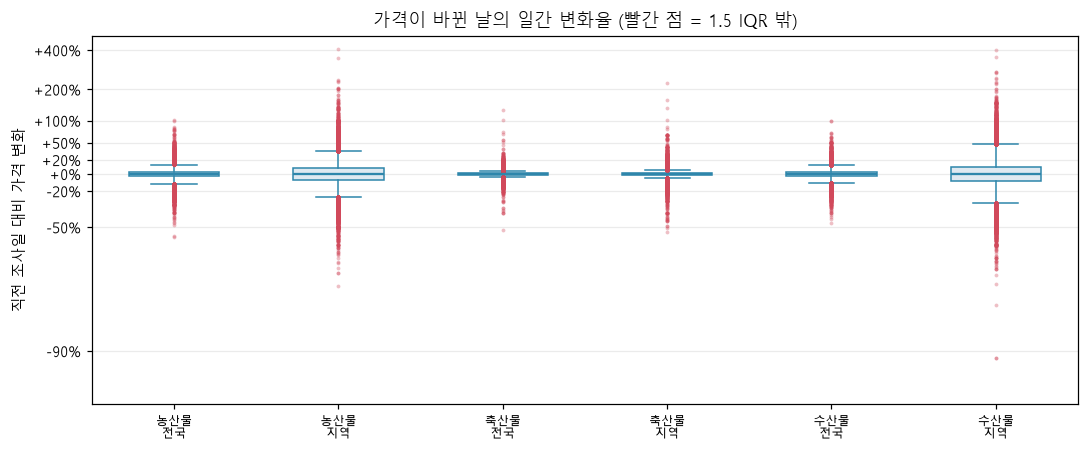

In [5]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.bxp(stats, widths=0.55, patch_artist=True, boxprops=dict(facecolor="#dfe9f1", edgecolor="#2e86ab"), medianprops=dict(color="#2e86ab", lw=1.5),
       whiskerprops=dict(color="#2e86ab"), capprops=dict(color="#2e86ab"),
       flierprops=dict(marker="o", markersize=2.5, markerfacecolor="#d1495b", markeredgecolor="none", alpha=0.35))
ax.set_xticks(range(1, len(labels) + 1), labels, fontsize=8)
ticks = [-0.9, -0.5, -0.2, 0, 0.2, 0.5, 1, 2, 4]
ax.set_yticks(np.log1p(ticks), [f"{t:+.0%}" for t in ticks]); ax.set_ylim(np.log1p(-0.95), np.log1p(5))
ax.set_ylabel("직전 조사일 대비 가격 변화"); ax.grid(axis="y", alpha=0.25)
ax.set_title("가격이 바뀐 날의 일간 변화율 (빨간 점 = 1.5 IQR 밖)"); plt.tight_layout()

## 2. 가장 큰 이상치 사례 (지역 가격)

직전 → 당일 → 다음 조사일 가격을 함께 보면, 다음 날 원래대로 돌아오는 **하루짜리 튐**(입력 오류 의심)과 실제 가격 변화를 구분할 수 있다.

In [6]:
ex = []
for d, s in ch.items():
    t = s[s.sgg_nm != "전국"].copy()
    lo, hi = fences(t.d.values)
    t["out"] = (t.d < lo) | (t.d > hi)
    t["after"] = t.out.groupby([t[k] for k in KEY], observed=True).shift(1, fill_value=False)   # 직전 이상치의 되돌림 쪽은 빼고
    o = t[t.out & ~t.after].assign(a=lambda x: x.d.abs()).nlargest(3, "a")
    ex += [{"분야": NAMES[d], "품목": f"{r.item_nm} {r.vrty_nm}", "지역": r.sgg_nm, "날짜": f"{r.date:%Y-%m-%d}",
            "직전 → 당일 → 다음 조사일 (원/kg)": f"{np.exp(r.prev):,.0f} → {r.price_kg:,.0f} → {np.exp(r.next):,.0f}"} for r in o.itertuples()]
pd.DataFrame(ex)

,분야,품목,지역,날짜,직전 → 당일 → 다음 조사일 (원/kg)
0,농산물,체리 수입,제주,2024-06-18,"17,700 → 2,000 → 19,900"
1,농산물,호박 쥬키니,울산,2025-01-31,"2,905 → 20,842 → 4,168"
2,농산물,오이 취청,성남,2024-09-10,"7,333 → 1,575 → 5,250"
3,축산물,닭 육계(kg),대전,2022-11-23,"5,364 → 536 → 5,364"
4,축산물,소 갈비,전남,2024-08-24,"83,370 → 35,000 → 35,000"
5,축산물,소 갈비,인천,2024-04-12,"26,000 → 60,000 → 60,000"
6,수산물,천일염 천일염,강릉,2026-04-09,"600 → 5,800 → 5,800"
7,수산물,천일염 천일염,김해,2026-02-02,"700 → 5,240 → 5,240"
8,수산물,갈치 국산(냉장),대전,2023-10-19,"77,143 → 14,000 → 14,000"


## 3. 하루짜리 튐은 얼마나 되나

직전 조사일 대비 1.5배 이상 튀었다가 다음 조사일에 원래 수준(±20%)으로 돌아온 날.

In [7]:
rows = []
for d, s in ch.items():
    spike = (s.d.abs() > np.log(1.5)) & ((s.next - s.prev).abs() < np.log(1.2))
    rows.append({"분야": NAMES[d], "가격이 바뀐 날": len(s), "하루짜리 튐": int(spike.sum()), "비율": spike.mean()})
pd.DataFrame(rows)

,분야,가격이 바뀐 날,하루짜리 튐,비율
0,농산물,824460,1055,0.001
1,축산물,425269,98,0.000
2,수산물,125413,422,0.003


## 4. 품목 하나 — 연도별 가격 상자그림 (소 · 세종)

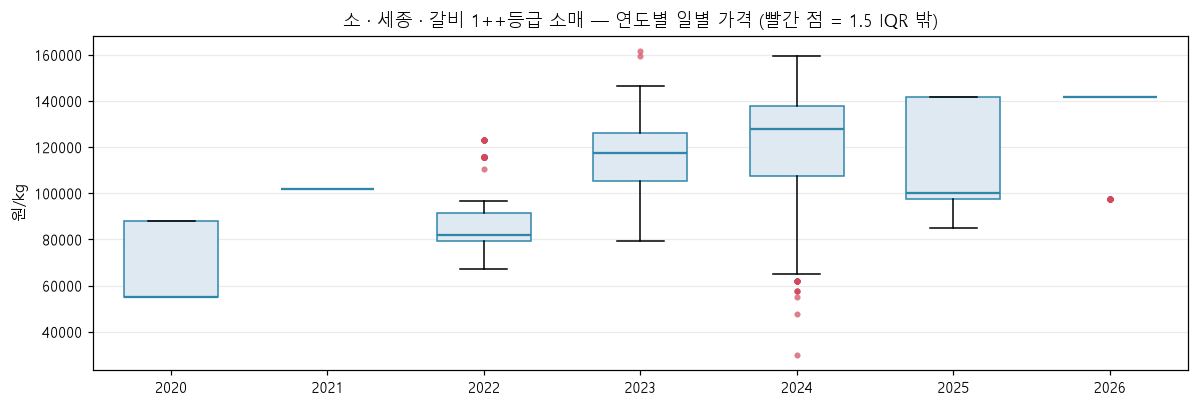

In [8]:
item, region = "소", "세종"
s = daily_prices("livestock", item, region)
s = s[s.se_nm == "소매"].assign(year=lambda x: x.date.dt.year)
s["dev"] = np.log(s.price_kg / s.groupby(["vrty_nm", "grd_nm", "year"]).price_kg.transform("median")).abs()
top = tuple(s.nlargest(1, "dev")[["vrty_nm", "grd_nm"]].iloc[0])          # 가장 크게 벗어난 값이 있는 품종·등급
s = s[(s.vrty_nm == top[0]) & (s.grd_nm == top[1])]
years = sorted(s.year.unique())
fig, ax = plt.subplots(figsize=(11, 3.8))
ax.boxplot([s.price_kg[s.year == y].values for y in years], tick_labels=[str(y) for y in years], widths=0.6, patch_artist=True,
           boxprops=dict(facecolor="#dfe9f1", edgecolor="#2e86ab"), medianprops=dict(color="#2e86ab", lw=1.5),
           flierprops=dict(marker="o", markersize=4, markerfacecolor="#d1495b", markeredgecolor="none", alpha=0.7))
ax.ticklabel_format(axis="y", style="plain"); ax.set_ylabel("원/kg"); ax.grid(axis="y", alpha=0.25)
ax.set_title(f"{item} · {region} · {top[0]} {top[1]} 소매 — 연도별 일별 가격 (빨간 점 = 1.5 IQR 밖)"); plt.tight_layout()

In [9]:
s.nlargest(5, "dev").assign(그해_중앙값_대비=lambda x: x.price_kg / x.year.map(s.groupby("year").price_kg.median()) - 1)[["date", "price_kg", "그해_중앙값_대비"]]

,date,price_kg,그해_중앙값_대비
854,2024-06-27,"30,000.000",-0.766
786,2024-04-20,"47,500.000",-0.629
857,2024-06-30,"55,000.000",-0.570
766,2024-03-31,"57,500.000",-0.551
767,2024-04-01,"57,500.000",-0.551
